# B05 怎样把带标签的文件整理成可复现的数据集？

建立文件清单并划分训练、验证、测试。模拟同一人的多条记录，说明随机按行切分会让同一人的信息泄漏到测试集；本例按人切分。

先修：B01—B04；Path、JSON、集合、不交集与随机种子。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 文件和标签是两种信息
生成小型教学文件，文件名不编码标签。标签表记录 sample_id、person_id 和 label；同一人的记录必须保持在同一划分。路径使用相对路径才能搬迁课程。

In [2]:
import json, hashlib
import pandas as pd
from sklearn.model_selection import train_test_split
sample_dir = DATA_DIR / 'samples'; sample_dir.mkdir(exist_ok=True)
rows = []
for person in range(30):
    label = person % 2
    for visit in range(2):
        sample_id = f'p{person:02d}_v{visit}'
        path = sample_dir / (sample_id + '.txt')
        path.write_text(f'Teaching record for person {person}, visit {visit}.', encoding='utf-8')
        rows.append({'sample_id': sample_id, 'person_id': person, 'label': label, 'path': path.relative_to(CASE_DIR).as_posix()})
manifest = pd.DataFrame(rows)
assert manifest['sample_id'].is_unique


## 2. 在独立单位上分层抽样
先取每人的一行信息，再分层保持类别比例。固定随机种子使同样的输入得到同样的名单；随机种子不能修复错误的划分单位。

In [3]:
people = manifest[['person_id', 'label']].drop_duplicates()
train_people, held_people = train_test_split(people, test_size=0.4, stratify=people['label'], random_state=5)
val_people, test_people = train_test_split(held_people, test_size=0.5, stratify=held_people['label'], random_state=5)
split_map = {}
for split, subset in [('train', train_people), ('validation', val_people), ('test', test_people)]:
    split_map.update({int(person): split for person in subset['person_id']})
manifest['split'] = manifest['person_id'].map(split_map)


## 3. 自动检查泄漏与内容版本
断言不同划分没有相同 person_id。SHA-256 用于发现内容改变，不是匿名化工具。检查每个文件存在，并把校验值随清单保存。

In [4]:
groups = {name: set(part['person_id']) for name, part in manifest.groupby('split')}
assert groups['train'].isdisjoint(groups['test'])
assert groups['train'].isdisjoint(groups['validation'])
assert groups['test'].isdisjoint(groups['validation'])
manifest['sha256'] = [hashlib.sha256((CASE_DIR / p).read_bytes()).hexdigest() for p in manifest['path']]
assert manifest['sha256'].str.len().eq(64).all()


## 4. 清单成为数据集入口
保存 JSON Lines 和 CSV，使训练脚本可以按 split 读取。输出类别计数图；如果数据具有时间关系，还应增加时间约束，本例仅演示独立人物分组。

In [5]:
manifest.to_json(OUT_DIR / 'manifest.jsonl', orient='records', lines=True, force_ascii=False)
manifest.to_csv(OUT_DIR / 'manifest.csv', index=False)
counts = pd.crosstab(manifest['split'], manifest['label'])
metrics = {'samples': len(manifest), 'people': len(people), 'counts': manifest['split'].value_counts().to_dict(), 'group_leakage': False}
(OUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
counts.plot.bar(); plt.ylabel('样本数'); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(OUT_DIR / 'splits.png'); plt.close(); print(counts)


label        0   1
split             
test         6   6
train       18  18
validation   6   6


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

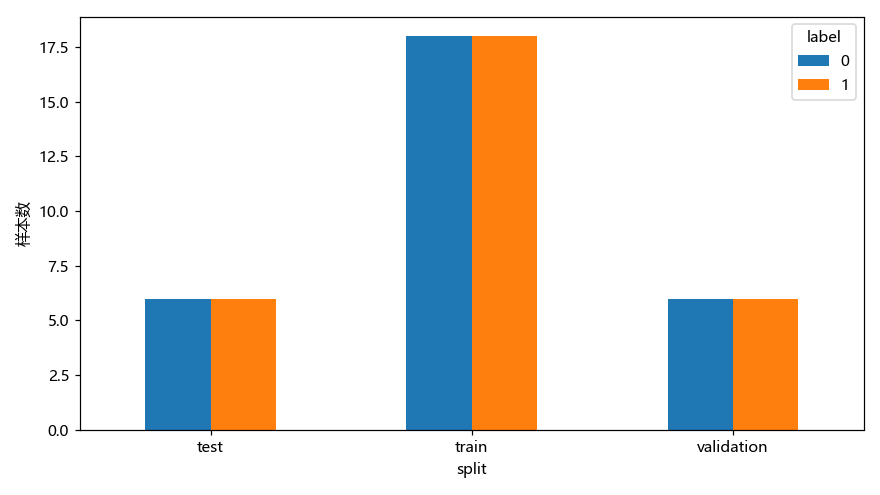

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
这些小文件仅用来练习清单，不是真实医疗或人体数据。按行随机划分可能把同一人物放进训练和测试。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。